# Statistical analysis for the correlation of RMSE and Newton iterations

In [147]:
from pathlib import Path
from scipy.io import loadmat

path = Path(
    r"C:\Users\giovanni\gnn\outputs"
    r"\CONFIGURATION_PAPER_REYNOLDS"
    r"\COMSOL Reynolds benchmark"
    r"\reynolds_benchmark_all_results.mat"
)

data = loadmat(
    path,
    simplify_cells=True
)

print("Variables:")
for key, value in data.items():
    if not key.startswith("__"):
        print(key, type(value))

Variables:
all_results <class 'list'>
dataset_file_used <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
model_file_used <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
reynolds_number <class 'numpy.ndarray'>
run_dir <class 'str'>
summary_table <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>


## Statistical dataset construction

In [148]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.io import loadmat

run_dir = Path(
    r"C:\Users\giovanni\gnn\outputs"
    r"\CONFIGURATION_PAPER_REYNOLDS"
)

benchmark_file = (
    run_dir
    / "COMSOL Reynolds benchmark"
    / "reynolds_benchmark_all_results.mat"
)

metrics_root = run_dir / "statistical_analysis"

benchmark = loadmat(
    benchmark_file,
    simplify_cells=True
)

results = benchmark["all_results"]
reynolds = np.asarray(
    benchmark["reynolds_number"]
).ravel().astype(int)

print("Reynolds:", reynolds)
print("Number of simulations:", len(results))

Reynolds: [200 180 160 140 120 100  80  60  40]
Number of simulations: 9


In [149]:
rows = []

for Re, result in zip(reynolds, results):

    metrics_dir = metrics_root / f"Re_{Re}"

    files = list(
        metrics_dir.glob("*rmse_over_time.npz")
    )

    if len(files) != 1:
        raise FileNotFoundError(
            f"Re={Re}: expected one metrics file, "
            f"found {len(files)}"
        )

    # ------------------------------------------
    # GNN prediction metrics
    # ------------------------------------------

    with np.load(files[0]) as metrics:

        indices = np.asarray(
            metrics["indices"]
        ).ravel().astype(int)

        # Corresponds to skip_initial = 0
        k_prediction = indices + 1

        df_gnn = pd.DataFrame({
            "k": k_prediction,
            "time_gnn": np.asarray(metrics["time"]).ravel(),
            "rmse_u": np.asarray(metrics["gnn_rmse_u"]).ravel(),
            "rmse_v": np.asarray(metrics["gnn_rmse_v"]).ravel(),
            "rmse_p": np.asarray(metrics["gnn_rmse_p"]).ravel(),
            "rmse_velocity": np.asarray(
                metrics["gnn_rmse_velocity"]
            ).ravel(),
            "baseline_rmse_velocity": np.asarray(
                metrics["baseline_rmse_velocity"]
            ).ravel(),
            "baseline_rmse_p": np.asarray(
                metrics["baseline_rmse_p"]
            ).ravel(),
        })

    # ------------------------------------------
    # COMSOL Newton results
    # ------------------------------------------

    df_newton = pd.DataFrame({
        "k": np.asarray(result["k"]).ravel().astype(int),
        "time": np.asarray(result["t_target"]).ravel(),
        "dt": np.asarray(result["dt"]).ravel(),
        "newton_standard": np.asarray(
            result["standard_iterations"]
        ).ravel(),
        "newton_gnn": np.asarray(
            result["gnn_iterations"]
        ).ravel(),
        "standard_converged": np.asarray(
            result["standard_converged"]
        ).ravel().astype(bool),
        "gnn_converged": np.asarray(
            result["gnn_converged"]
        ).ravel().astype(bool),
    })

    # ------------------------------------------
    # Merge using transition index
    # ------------------------------------------

    df_re = df_newton.merge(
        df_gnn,
        on="k",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    if not (df_re["_merge"] == "both").all():
        raise ValueError(
            f"Missing GNN predictions for Re={Re}"
        )

    if not np.allclose(
        df_re["time"],
        df_re["time_gnn"],
        atol=1e-6,
        rtol=0
    ):
        raise ValueError(
            f"Time mismatch for Re={Re}"
        )

    df_re = df_re.drop(
        columns=["time_gnn", "_merge"]
    )

    df_re["Re"] = Re
    df_re["initial_guess"] = str(result["initial_guess"])
    df_re["bdf_order"] = int(result["bdf_order"])

    rows.append(df_re)

df = pd.concat(rows, ignore_index=True)

print("Merged dataset:", df.shape)
display(df.head())

df["iterations_saved"] = (
    df["newton_standard"] - df["newton_gnn"]
)

df["both_converged"] = (
    df["standard_converged"]
    & df["gnn_converged"]
)

# Relative iteration reduction
df["iteration_reduction_percent"] = np.where(
    df["newton_standard"] > 0,
    100 * df["iterations_saved"] / df["newton_standard"],
    np.nan
)

# Prediction improvement over standard initial guess
df["velocity_rmse_gain"] = np.where(
    df["rmse_velocity"] > 0,
    df["baseline_rmse_velocity"] / df["rmse_velocity"],
    np.nan
)

df["pressure_rmse_gain"] = np.where(
    df["rmse_p"] > 0,
    df["baseline_rmse_p"] / df["rmse_p"],
    np.nan
)
df_analysis = df[
    (df["k"] >= 6) &
    (df["both_converged"])
].copy()

print("Full dataset:", len(df))
print("Analysis dataset:", len(df_analysis))

print("\nTransitions per Reynolds:")
print(df_analysis.groupby("Re").size())


Merged dataset: (3141, 16)


,k,time,dt,newton_standard,newton_gnn,standard_converged,gnn_converged,rmse_u,rmse_v,rmse_p,rmse_velocity,baseline_rmse_velocity,baseline_rmse_p,Re,initial_guess,bdf_order
0,2,0.04,0.02,7.0,7.0,True,True,0.519750,0.056426,26.966983,0.522804,0.524716,26.636446,200,gnn,2
1,3,0.06,0.02,8.0,8.0,True,True,0.724232,0.083618,21.955074,0.729043,0.744008,21.528707,200,gnn,2
2,4,0.08,0.02,8.0,8.0,True,True,0.516604,0.077435,26.408000,0.522375,0.543417,26.855249,200,gnn,2
3,5,0.10,0.02,8.0,8.0,True,True,0.149522,0.064883,32.781898,0.162993,0.168936,33.205902,200,gnn,2
4,6,0.12,0.02,9.0,9.0,True,True,0.028569,0.020090,2.521426,0.034926,0.112834,1.202242,200,gnn,2


Full dataset: 3141
Analysis dataset: 3100

Transitions per Reynolds:
Re
40     345
60     344
80     345
100    344
120    345
140    344
160    345
180    343
200    345
dtype: int64


In [150]:
# No duplicate transitions
assert not df.duplicated(["Re", "k"]).any()

# Every Reynolds has its expected transitions
for Re, group in df.groupby("Re"):
    assert len(group) == 349, (
        f"Unexpected number of transitions for Re={Re}"
    )

# Physical RMSE cannot be negative
rmse_columns = [
    "rmse_u",
    "rmse_v",
    "rmse_p",
    "rmse_velocity",
    "baseline_rmse_velocity",
    "baseline_rmse_p",
]

assert (df[rmse_columns] >= 0).all().all()

# Check that stored iteration savings are consistent
for Re, result in zip(reynolds, results):
    group = df[df["Re"] == Re].sort_values("k")

    np.testing.assert_allclose(
        group["iterations_saved"].to_numpy(),
        np.asarray(result["iterations_saved"]).ravel(),
        equal_nan=True
    )

print("All validation checks passed!")

All validation checks passed!


In [151]:
output_dir = metrics_root
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_dir / "gnn_newton_full_dataset.csv",
    index=False
)

df_analysis.to_csv(
    output_dir / "gnn_newton_analysis_dataset.csv",
    index=False
)

print("Datasets saved successfully.")

Datasets saved successfully.


## Visualization of the data

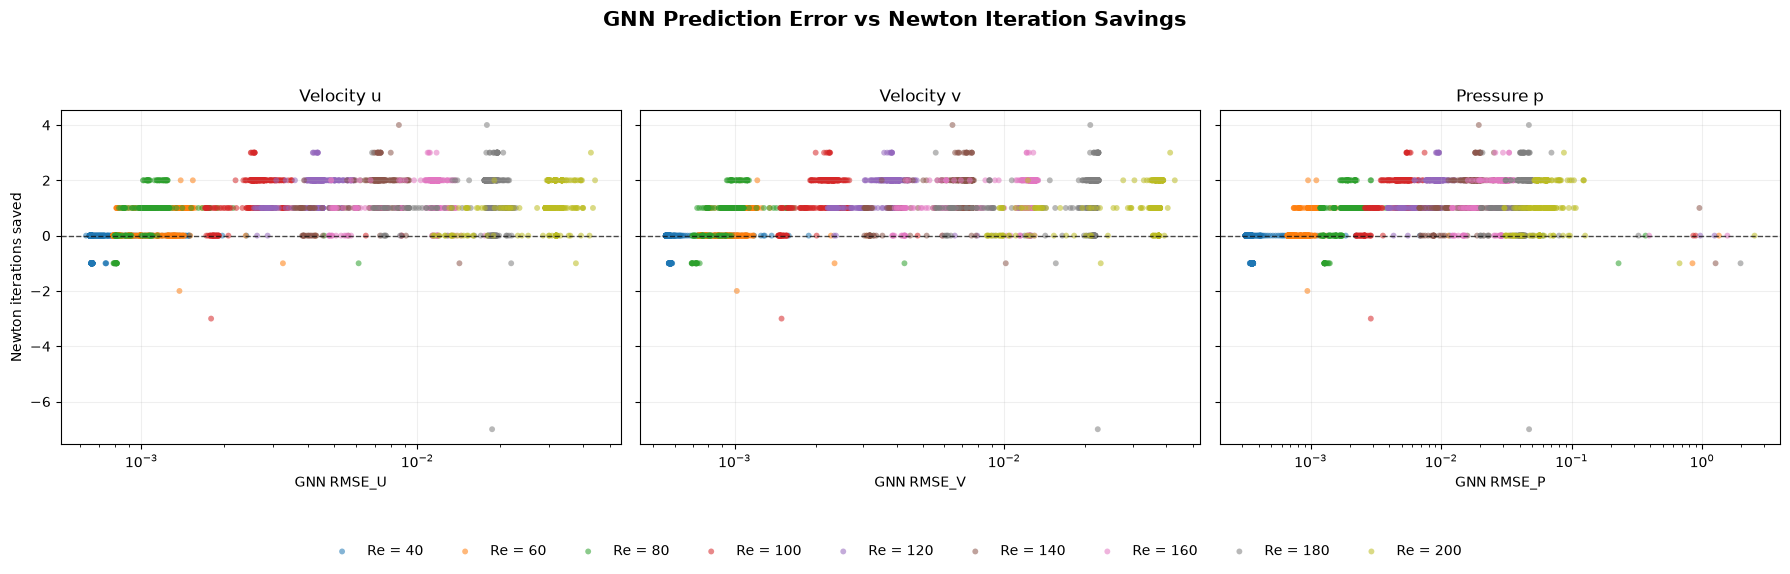

In [152]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset filtered: k >= 6, both solvers converged
plot_df = df_analysis.copy()

rmse_columns = ["rmse_u", "rmse_v", "rmse_p"]
titles = [
    "Velocity u",
    "Velocity v",
    "Pressure p"
]

reynolds_values = sorted(plot_df["Re"].unique())

# One distinct color for each Reynolds number
cmap = plt.get_cmap("tab10")
colors = {
    Re: cmap(i)
    for i, Re in enumerate(reynolds_values)
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5),
    sharey=True
)

for ax, column, title in zip(axes, rmse_columns, titles):

    for Re in reynolds_values:

        subset = plot_df[plot_df["Re"] == Re]

        ax.scatter(
            subset[column],
            subset["iterations_saved"],
            color=colors[Re],
            label=f"Re = {Re}",
            alpha=0.55,
            s=18,
            edgecolors="none"
        )

    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.7
    )

    ax.set_xlabel(f"GNN {column.upper()}")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.set_xscale("log")

axes[0].set_ylabel("Newton iterations saved")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=9,
    frameon=False
)

fig.suptitle(
    "GNN Prediction Error vs Newton Iteration Savings",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

There is not a strict positive correlation among the number of Iterations saved and the RMSE of the different quantitities. Howeever, what can be seen quite clearly is that the transitions with higher Reynolds number present a higher RMSE, but the number of Newton iterations saved seems to be comparable among the different datasets, suggesting that when the Reynolds number increases even a smaller improvement can bring some good results.

### Let's consider the gain in terms of the ratio of the current rmse against the baseline rmse

In [153]:
df_analysis = df_analysis.copy()

df_analysis["rmse_gain_velocity"] = (
    df_analysis["rmse_velocity"]/df_analysis["baseline_rmse_velocity"]
)

df_analysis["rmse_gain_p"] = (
     df_analysis["rmse_p"]/df_analysis["baseline_rmse_p"]
)

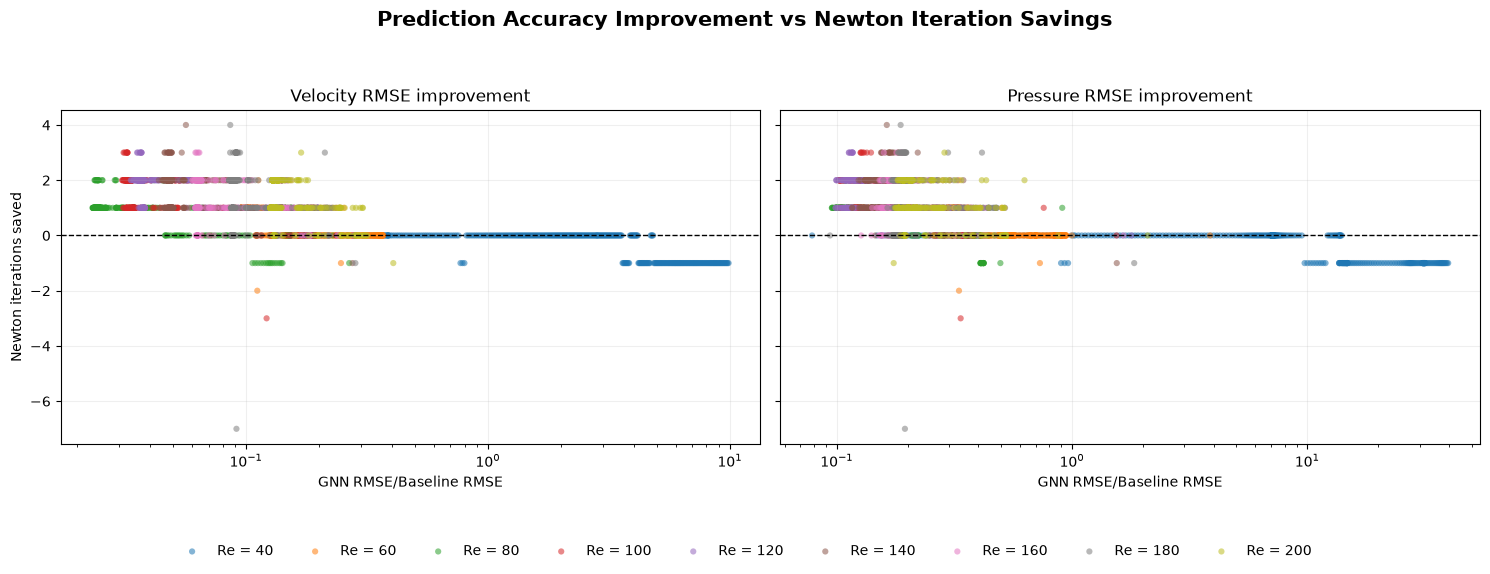

In [154]:
import matplotlib.pyplot as plt
import numpy as np

variables = [
    "rmse_gain_velocity",
    "rmse_gain_p"
]

titles = [
    "Velocity RMSE improvement",
    "Pressure RMSE improvement"
]

reynolds_values = sorted(df_analysis["Re"].unique())

cmap = plt.get_cmap("tab10")
colors = {
    Re: cmap(i)
    for i, Re in enumerate(reynolds_values)
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5.5),
    sharey=True
)

for ax, variable, title in zip(axes, variables, titles):

    for Re in reynolds_values:

        subset = df_analysis[
            df_analysis["Re"] == Re
        ]

        ax.scatter(
            subset[variable],
            subset["iterations_saved"],
            color=colors[Re],
            label=f"Re = {Re}",
            alpha=0.55,
            s=20,
            edgecolors="none"
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(0, color="gray", linestyle=":", linewidth=1)

    ax.set_xlabel("GNN RMSE/Baseline RMSE")

    ax.set_xscale("log")

    ax.set_title(title)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Newton iterations saved")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=9,
    frameon=False
)

fig.suptitle(
    "Prediction Accuracy Improvement vs Newton Iteration Savings",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

It can be seen quite clearly the difficulty for the 40 Re simulation to improve the baseline initial guess given the almost stationary behaviour.

## Spearman correlation

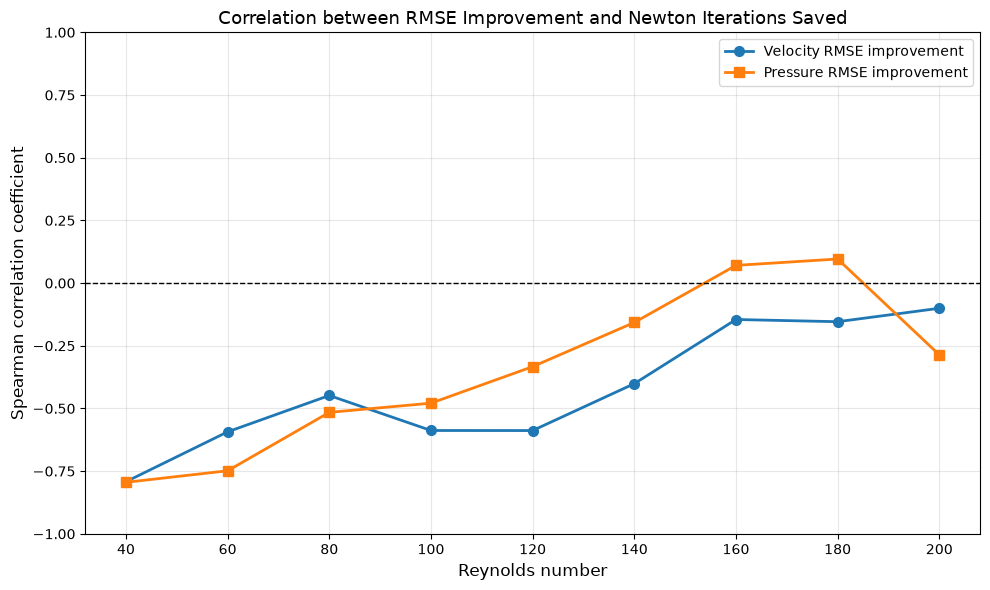

In [155]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Store correlations
correlations = []

for Re, group in df_analysis.groupby("Re"):

    for variable in ["rmse_gain_velocity", "rmse_gain_p"]:

        valid = group[
            [variable, "iterations_saved"]
        ].dropna()

        if (
            valid[variable].nunique() < 2
            or valid["iterations_saved"].nunique() < 2
        ):
            rho = np.nan
        else:
            rho, _ = spearmanr(
                valid[variable],
                valid["iterations_saved"]
            )

        correlations.append({
            "Re": Re,
            "Variable": variable,
            "Spearman": rho
        })

# Convert to DataFrame
corr_df = pd.DataFrame(correlations)

corr_plot = corr_df.pivot(
    index="Re",
    columns="Variable",
    values="Spearman"
).sort_index()

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    corr_plot.index,
    corr_plot["rmse_gain_velocity"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Velocity RMSE improvement"
)

ax.plot(
    corr_plot.index,
    corr_plot["rmse_gain_p"],
    marker="s",
    linewidth=2,
    markersize=7,
    label="Pressure RMSE improvement"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Reynolds number", fontsize=12)
ax.set_ylabel("Spearman correlation coefficient", fontsize=12)

ax.set_title(
    "Correlation between RMSE Improvement and Newton Iterations Saved",
    fontsize=13
)

ax.set_xticks(corr_plot.index)
ax.set_ylim(-1, 1)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

The Spearman correlation analysis reveals that the relationship between GNN prediction RMSE and Newton iteration savings is not consistently negative across Reynolds numbers. The results suggests that prediction accuracy alone does not fully characterize the effectiveness of a GNN-based initialization, especially as the Reynolds number increases.

# Probability analysis of improvement

In [156]:
import pandas as pd

df_analysis = df_analysis.copy()

df_analysis["velocity_improved"] = df_analysis["rmse_gain_velocity"] > 0
df_analysis["pressure_improved"] = df_analysis["rmse_gain_p"] > 0
df_analysis["newton_improved"] = df_analysis["iterations_saved"] > 0

contingency_results = {}

for Re, group in df_analysis.groupby("Re"):

    contingency_results[Re] = {}

    for variable in ["velocity_improved", "pressure_improved"]:

        contingency = pd.crosstab(
            group[variable],
            group["newton_improved"]
        ).reindex(
            index=[False, True],
            columns=[False, True],
            fill_value=0
        )

        percentages = contingency.div(
            contingency.sum(axis=1).replace(0, float("nan")),
            axis=0
        ) * 100

        contingency_results[Re][variable] = {
            "counts": contingency,
            "percentages": percentages
        }

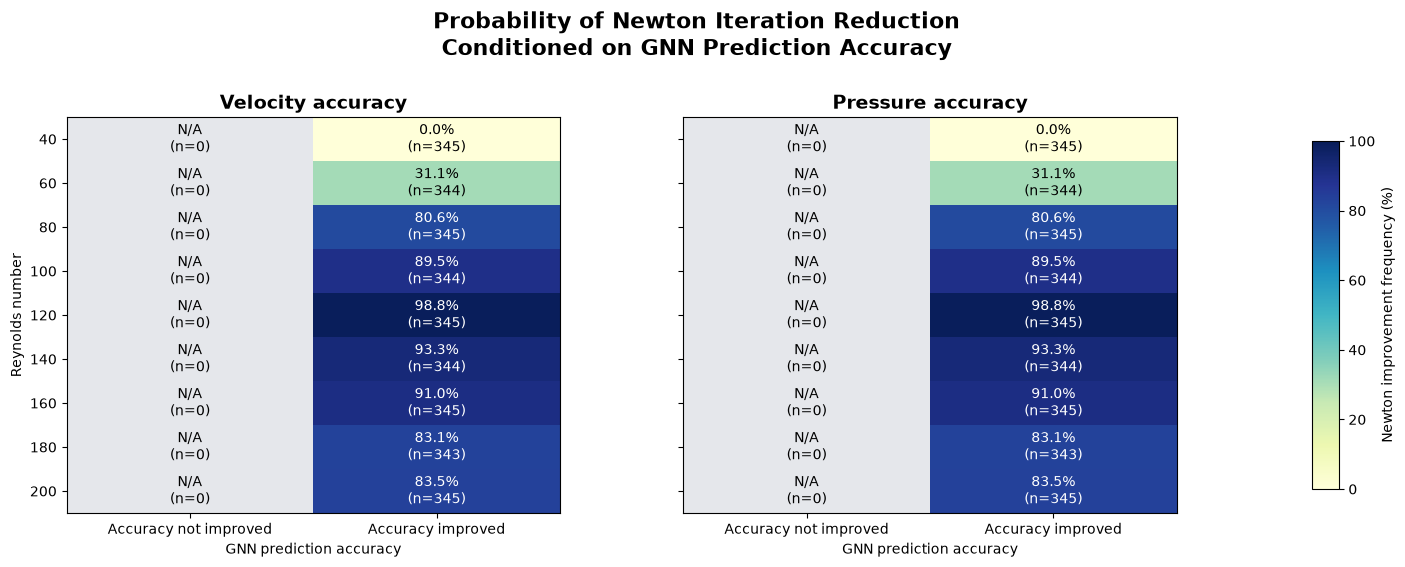

In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Work on a copy
plot_df = df_analysis.copy()

plot_df["velocity_improved"] = plot_df["rmse_gain_velocity"] > 0
plot_df["pressure_improved"] = plot_df["rmse_gain_p"] > 0
plot_df["newton_improved"] = plot_df["iterations_saved"] > 0

reynolds = sorted(plot_df["Re"].unique())

variables = [
    ("velocity_improved", "Velocity accuracy"),
    ("pressure_improved", "Pressure accuracy")
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharey=True
)

cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#E5E7EB")

for ax, (variable, title) in zip(axes, variables):

    probabilities = np.full((len(reynolds), 2), np.nan)
    counts = np.zeros((len(reynolds), 2), dtype=int)

    for i, Re in enumerate(reynolds):

        group = plot_df[plot_df["Re"] == Re]

        for j, accuracy_improved in enumerate([False, True]):

            subset = group[
                group[variable] == accuracy_improved
            ]

            counts[i, j] = len(subset)

            if len(subset) > 0:
                probabilities[i, j] = (
                    100 * subset["newton_improved"].mean()
                )

    im = ax.imshow(
        probabilities,
        cmap=cmap,
        norm=Normalize(vmin=0, vmax=100),
        aspect="auto"
    )

    ax.set_title(title, fontsize=14, fontweight="bold")

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        "Accuracy not improved",
        "Accuracy improved"
    ])

    ax.set_yticks(range(len(reynolds)))
    ax.set_yticklabels(reynolds)

    ax.set_xlabel("GNN prediction accuracy")

    for i in range(len(reynolds)):
        for j in range(2):

            value = probabilities[i, j]
            n = counts[i, j]

            if np.isnan(value):
                label = "N/A\n(n=0)"
                color = "black"
            else:
                label = f"{value:.1f}%\n(n={n})"
                color = "white" if value >= 65 else "black"

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                fontsize=10,
                color=color
            )

axes[0].set_ylabel("Reynolds number")

fig.suptitle(
    "Probability of Newton Iteration Reduction\n"
    "Conditioned on GNN Prediction Accuracy",
    fontsize=16,
    fontweight="bold"
)

# Reserve space on the right for the colorbar
fig.subplots_adjust(
    left=0.08,
    right=0.82,
    bottom=0.14,
    top=0.80,
    wspace=0.25
)

# Create a dedicated axis for the colorbar
cbar_ax = fig.add_axes([0.91, 0.18, 0.018, 0.58])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_label("Newton improvement frequency (%)")

plt.show()

It seems that on the extreme Reynolds numbers the improvement becomes more difficult to obtain, especially for low Re. More details about the interpretation of this phenomenon can be found in the report

# Outlier analysis and interpretation

In [158]:
import numpy as np
import pandas as pd

df_outliers = df_analysis.copy()

df_outliers["performance_group"] = np.select(
    [
        df_outliers["iterations_saved"] >= 3,
        df_outliers["iterations_saved"] <= -2
    ],
    [
        "Strong improvement",
        "Strong deterioration"
    ],
    default="Typical"
)

summary = pd.crosstab(
    df_outliers["Re"],
    df_outliers["performance_group"]
)

display(summary)

performance_group,Strong deterioration,Strong improvement,Typical
Re,,,
40,0,0,345
60,1,0,343
80,0,0,345
100,1,8,335
120,0,8,337
140,0,15,329
160,0,4,341
180,1,22,320
200,0,1,344


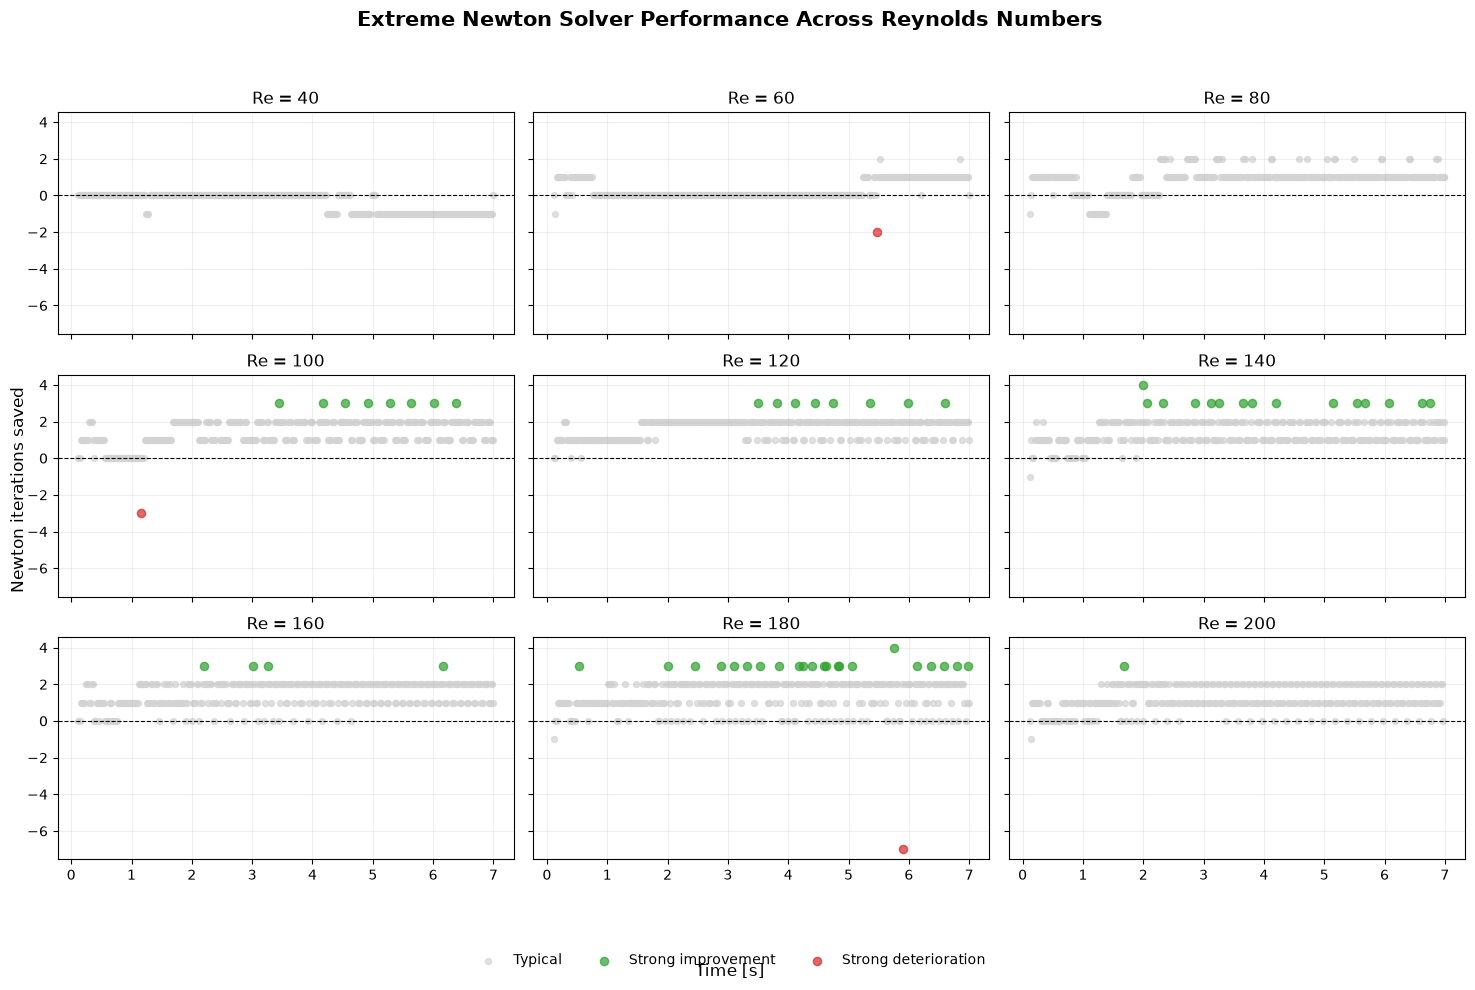

In [159]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 10),
    sharex=True,
    sharey=True
)

colors = {
    "Strong improvement": "tab:green",
    "Strong deterioration": "tab:red",
    "Typical": "lightgray"
}

for ax, (Re, group) in zip(
    axes.flat,
    df_outliers.groupby("Re")
):

    for category in [
        "Typical",
        "Strong improvement",
        "Strong deterioration"
    ]:

        subset = group[
            group["performance_group"] == category
        ]

        ax.scatter(
            subset["time"],
            subset["iterations_saved"],
            color=colors[category],
            s=18 if category == "Typical" else 35,
            alpha=0.7,
            label=category
        )

    ax.axhline(0, color="black", linestyle="--", lw=0.8)
    ax.set_title(f"Re = {Re}")
    ax.grid(alpha=0.2)

fig.supxlabel("Time [s]")
fig.supylabel("Newton iterations saved")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Extreme Newton Solver Performance Across Reynolds Numbers",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()

In [164]:
features = [
    "rmse_gain_velocity",
    "rmse_gain_p",
    "rmse_velocity",
    "rmse_p",
    "baseline_rmse_velocity",
    "baseline_rmse_p",
    "newton_standard"
]

summary_features = (
    df_outliers
    .groupby("performance_group")[features]
    .median()
)



## Leet's focus on the negative outliers

In [ ]:
extreme_cases = df_outliers[
    df_outliers["performance_group"] != "Typical"
].copy()

negative_outliers = (
    df_analysis[df_analysis["iterations_saved"] <= -2]
    .sort_values("iterations_saved")
)

Selected outlier: Re=180, k=295
Newton iterations saved: -7
Velocity RMSE gain: 9.1303e-02
Pressure RMSE gain: 1.9486e-01

Evaluating C:\Users\giovanni\.comsol\v64\llmatlab\channel2d_manual_stabilization_180R.mat (external dataset supplied on the command line)

Training skip_initial  : 5
Inference skip_initial : 0
Physical target times after skip_initial=0: 2.000000e-02 -> 7.000000e+00 s
  C:\Users\giovanni\.comsol\v64\llmatlab\channel2d_manual_stabilization_180R.mat
  5811 nodes | 34090 edges | 351 samples, of which 351 were held out by the 'all_train' split
Visualization triangulation: 11256 triangles | 22 removed | 11234 retained


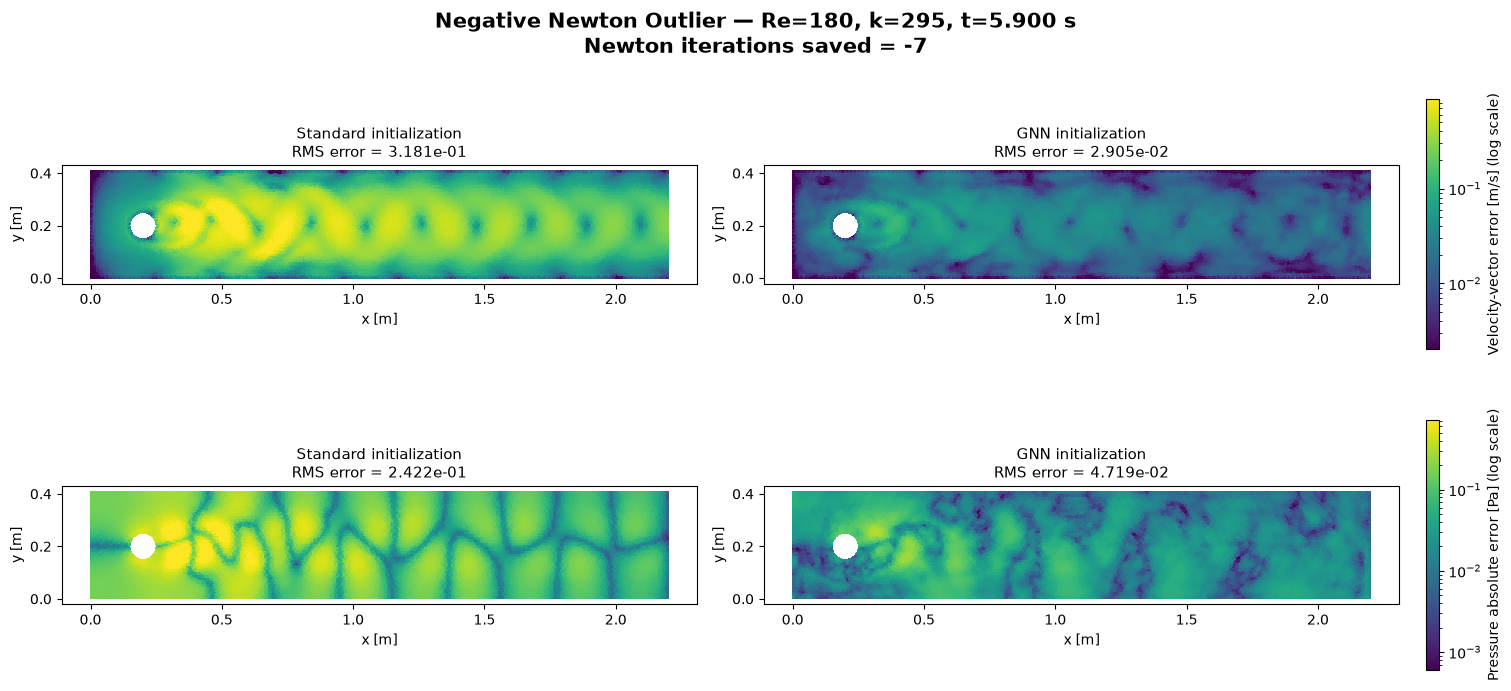

In [167]:
import sys
from pathlib import Path
from matplotlib.colors import LogNorm
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# ============================================================
# 1. IMPORT ORIGINAL GNN-COMSOL FUNCTIONS
# ============================================================

project_root = Path(r"C:\Users\giovanni\gnn")

sys.path.insert(0, str(project_root / "src"))

from gnn_comsol.evaluation import (
    read_run,
    prepare_evaluation_data,
)

from gnn_comsol.evaluation.visualization import mesh_triangulation


# ============================================================
# 2. PATHS
# ============================================================

run_dir = (
    project_root
    / "outputs"
    / "CONFIGURATION_PAPER_REYNOLDS"
)

metrics_root = run_dir / "statistical_analysis"

dataset_root = Path(
    r"C:\Users\giovanni\.comsol\v64\llmatlab"
)


# ============================================================
# 3. SELECT WORST NEGATIVE OUTLIER
# ============================================================

negative_outliers = (
    df_analysis[
        df_analysis["iterations_saved"] < 0
    ]
    .sort_values("iterations_saved")
)

if negative_outliers.empty:
    raise ValueError("No negative Newton outliers found.")

worst = negative_outliers.iloc[0]

Re = int(worst["Re"])
k = int(worst["k"])

print(f"Selected outlier: Re={Re}, k={k}")
print(f"Newton iterations saved: {worst['iterations_saved']:+.0f}")
print(f"Velocity RMSE gain: {worst['rmse_gain_velocity']:.4e}")
print(f"Pressure RMSE gain: {worst['rmse_gain_p']:.4e}")


# ============================================================
# 4. LOAD SAVED PREDICTIONS
# ============================================================

prediction_file = (
    metrics_root
    / f"Re_{Re}"
    / "gnn_predictions.mat"
)

if not prediction_file.is_file():
    raise FileNotFoundError(prediction_file)

data_pred = loadmat(
    prediction_file,
    simplify_cells=True
)

transition_indices = np.asarray(
    data_pred["transition_index"]
).ravel().astype(int)

matching = np.flatnonzero(transition_indices == k)

if len(matching) != 1:
    raise ValueError(
        f"Expected one prediction for Re={Re}, k={k}; "
        f"found {len(matching)}"
    )

idx = matching[0]

pos = np.asarray(data_pred["node_coordinates"])


# ============================================================
# 5. LOAD ORIGINAL EVALUATION MESH
# ============================================================

config, metrics = read_run(run_dir)

dataset_path = (
    dataset_root
    / f"channel2d_manual_stabilization_{Re}R.mat"
)

(
    evaluation,
    _,
    _,
    time,
    indices,
    report_mask,
    inference_skip_initial,
) = prepare_evaluation_data(
    config=config,
    metrics=metrics,
    dataset_override=str(dataset_path),
    simulation_id=None,
    skip_initial=0,
    held_out_only=False,
)

# Verify node ordering
np.testing.assert_allclose(
    np.asarray(evaluation.pos),
    pos,
    rtol=0,
    atol=1e-10
)

# Original triangulation: respects cylinder geometry
triang = mesh_triangulation(evaluation)


# ============================================================
# 6. EXTRACT FIELDS FOR THE SELECTED TRANSITION
# ============================================================

def get_field(name):
    return np.asarray(data_pred[name][idx]).ravel()


u_pred = get_field("u_pred")
v_pred = get_field("v_pred")
p_pred = get_field("p_pred")

u_input = get_field("u_input")
v_input = get_field("v_input")
p_input = get_field("p_input")

u_target = get_field("u_target")
v_target = get_field("v_target")
p_target = get_field("p_target")


# ============================================================
# 7. COMPUTE SPATIAL ERRORS
# ============================================================

# Velocity-vector error magnitude
velocity_error_standard = np.sqrt(
    (u_input - u_target)**2
    + (v_input - v_target)**2
)

velocity_error_gnn = np.sqrt(
    (u_pred - u_target)**2
    + (v_pred - v_target)**2
)

# Pressure absolute error
pressure_error_standard = np.abs(
    p_input - p_target
)

pressure_error_gnn = np.abs(
    p_pred - p_target
)


# ============================================================
# 8. PLOT: LOGARITHMIC COLOR SCALE
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 7),
    constrained_layout=True
)

fields = [
    [velocity_error_standard, velocity_error_gnn],
    [pressure_error_standard, pressure_error_gnn]
]

row_labels = [
    "Velocity-vector error [m/s]",
    "Pressure absolute error [Pa]"
]

column_labels = [
    "Standard initialization",
    "GNN initialization"
]

for row in range(2):

    # Shared logarithmic color scale for each physical quantity
    combined = np.concatenate([
        fields[row][0].ravel(),
        fields[row][1].ravel()
    ])

    positive = combined[
        np.isfinite(combined) & (combined > 0)
    ]

    if positive.size == 0:
        raise ValueError("No positive errors available for LogNorm.")

    # Robust color limits
    vmin = np.percentile(positive, 1)
    vmax = np.percentile(positive, 99)

    if vmax <= vmin:
        vmin = positive.min()
        vmax = positive.max()

    if vmax <= vmin:
        vmax = vmin * 10

    norm = LogNorm(vmin=vmin, vmax=vmax)

    for col in range(2):

        ax = axes[row, col]
        field = fields[row][col]

        im = ax.tripcolor(
            triang,
            field,
            shading="flat",
            cmap="viridis",
            norm=norm
        )

        rms = np.sqrt(np.mean(field**2))

        ax.set_title(
            f"{column_labels[col]}\n"
            f"RMS error = {rms:.3e}",
            fontsize=11
        )

        ax.set_aspect("equal")
        ax.set_xlabel("x [m]")
        ax.set_ylabel("y [m]")

    fig.colorbar(
        im,
        ax=axes[row, :],
        shrink=0.8,
        pad=0.02,
        label=row_labels[row] + " (log scale)"
    )

fig.suptitle(
    f"Negative Newton Outlier — Re={Re}, k={k}, "
    f"t={float(worst['time']):.3f} s\n"
    f"Newton iterations saved = {worst['iterations_saved']:+.0f}",
    fontsize=15,
    fontweight="bold"
)

plt.show()

In terms of data loss, I can't see any particular behaviour.

Residuals of u, v and p respectively after 1 iteration with the GNN initialization, it does not seem to have particular anomalies. This underlies an important inherent difficulty of this project, the behaviour of Newton's method is not always easily interpretable and possibly a more structured and detailed analysis on what is happening inside the solver for this outlier cases might bring some useful insights also for the design of the GNN. 

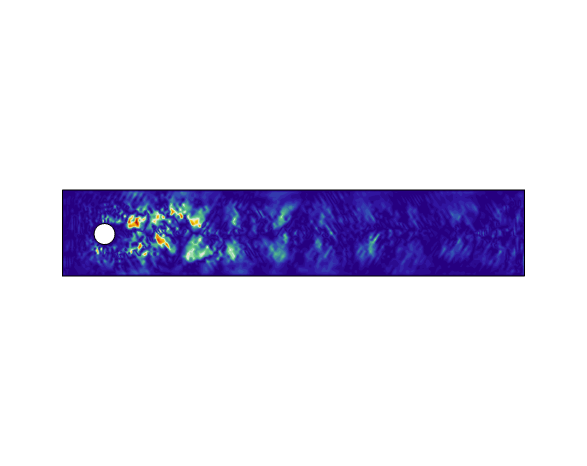 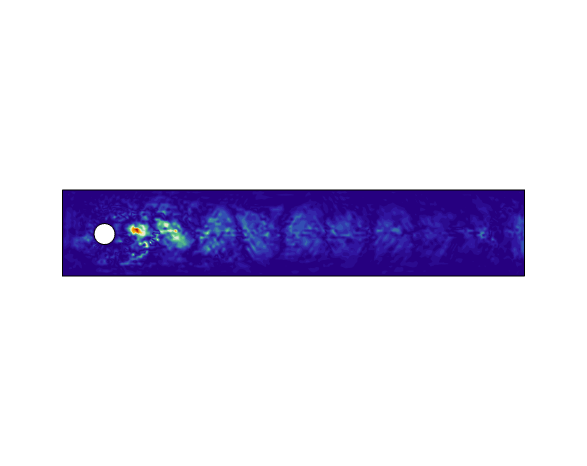 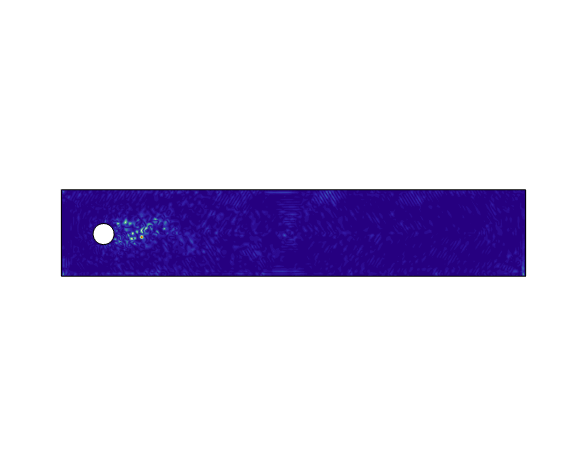